## Length estimation

First, install the environment with uv, see `install.md`

Select the python environment installed in .venv

Detect the ruler(s) on each sheet in `dataset/sample_images`, match it, and show the scale factor in millimeters.

Change the IMAGE_DIR parameter to run on your own images.


In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from loguru import logger

# Default log level. Set to "DEBUG" to see more info.
logger.remove()
logger.add(sys.stderr, level="INFO")

ROOT = Path.cwd().resolve()
if not (ROOT / "scale_estimation" / "default_config.json").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from scale_estimation.engine import RulerInference, load_config
from scale_estimation.utils import (
    crop_rulers_from_coco,
    ensure_horizontal_image,
    load_rgb_image,
    visualize_ruler_crop,
)

IMAGE_DIR = ROOT / "dataset" / "sample_images"
OUTPUT_DIR = ROOT / "outputs" / "length_estimation"
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".webp"}
THRESHOLD = 0.5

print(ROOT)


/home/kenzo/herbaria/scale-estimation


RF-DETR finds the ruler polygon. The matcher then estimates millimeters per pixel.

In [2]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cfg = load_config(ROOT / "scale_estimation" / "default_config.json")
cfg["target_unit"] = "mm"
engine = RulerInference(**cfg)
engine.detection_threshold = THRESHOLD
if not engine.detection_model_path.is_file():
    raise FileNotFoundError(engine.detection_model_path)

print(f"Detection model: {engine.detection_model_path}")
print(f"Embedding model: {engine.embedding_model_name} loaded")
print(f"Matcher model: {engine.matcher_model_name} loaded")
print(f"Target unit: {engine.target_unit}")


2026-10-14 18:15:26.289 | INFO     | scale_estimation.engine:__init__:606 - Initializing RulerInference
2026-10-14 18:15:26.402 | INFO     | scale_estimation.engine:__init__:636 - Config: base_dir=/home/kenzo/herbaria/scale-estimation | reference_dir=/home/kenzo/herbaria/scale-estimation/dataset/merged_ruler_crops_normalized | device=cuda | target_unit=mm | strict=False | embedding=dino | matcher=loma
2026-10-14 18:15:26.403 | INFO     | scale_estimation.engine:__init__:649 - dino: dinov3-vitl16-pretrain-lvd1689m (top_k=3) | loma: min_matches=10 top_k_matches=100 | RANSAC: method=USAC_MAGSAC iters=100000 reproj=0.5 conf=0.999
2026-10-14 18:15:30.281 | INFO     | scale_estimation.engine:_load_models:787 - Loading DINO model from /home/kenzo/herbaria/scale-estimation/models/dinov3-vitl16-pretrain-lvd1689m


Loading weights:   0%|          | 0/415 [00:00<?, ?it/s]

2026-10-14 18:15:33.323 | INFO     | scale_estimation.engine:_load_models:814 - Loading LoMa matcher LoMa_B (filter_threshold=0.5)
2026-10-14 18:15:42.908 | INFO     | scale_estimation.engine:_load_index:848 - Loading reference embeddings from /home/kenzo/herbaria/scale-estimation/dataset/embeddings_dinov3-vitl16-pretrain-lvd1689m_custom.h5
2026-10-14 18:15:43.032 | INFO     | scale_estimation.engine:_load_index:853 - Loaded 1996 reference embeddings (dim=1024)
2026-10-14 18:15:43.033 | INFO     | scale_estimation.engine:_load_index:861 - Loading Annoy index from /home/kenzo/herbaria/scale-estimation/dataset/dino_annoy_index_custom.ann
2026-10-14 18:15:43.034 | INFO     | scale_estimation.engine:__init__:693 - RulerInference ready


Detection model: /home/kenzo/herbaria/scale-estimation/models/rf_detr_seg_nano_rulers.pth
Embedding model: dino loaded
Matcher model: loma loaded
Target unit: mm


#### Visualization functions

In [8]:
TITLE_SIZE = 24


def tick_caption(label):
    text = str(label).removeprefix("ticks_")
    return text


def tick_anchor(tick_label, width, height, rotated):
    data = tick_label if isinstance(tick_label, dict) else tick_label.to_dict()
    points = np.asarray(data["normalized_points"], dtype=np.float32)
    if rotated:
        points = np.array([width - 1, height - 1], dtype=np.float32) - points
    anchor = points[len(points) // 2]
    return float(anchor[0]), float(anchor[1])


def show_result(image_path, coco, result):
    sheet = load_rgb_image(image_path)
    crops = crop_rulers_from_coco(sheet, coco)
    best = result.match_results[0] if result.match_results else None

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(sheet)
    title = f"{image_path.name}  {result.status}"
    if result.scale_factor is not None:
        title += f"  {result.scale_factor:.4g} {engine.target_unit}/px"
    axes[0].set_title(title, fontsize=TITLE_SIZE, pad=14)

    for _, bbox, _ in crops:
        x1, y1, x2, y2 = bbox
        axes[0].add_patch(
            plt.Rectangle(
                (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="orange", linewidth=1
            )
        )

    crop = None
    if best is not None and best.ruler_bbox_xyxy is not None:
        x1, y1, x2, y2 = [int(v) for v in best.ruler_bbox_xyxy]
        axes[0].add_patch(
            plt.Rectangle(
                (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=2
            )
        )
        crop = sheet[y1:y2, x1:x2]
    elif crops:
        crop, bbox, _ = crops[0]
        x1, y1, x2, y2 = bbox
        axes[0].add_patch(
            plt.Rectangle(
                (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=2
            )
        )

    axes[0].axis("off")
    if crop is not None and crop.size:
        axes[1].imshow(crop)
        axes[1].set_title("Best ruler crop", fontsize=TITLE_SIZE, pad=14)
    else:
        axes[1].set_title("No ruler crop", fontsize=TITLE_SIZE, pad=14)
    axes[1].axis("off")
    fig.tight_layout()
    display(fig)
    plt.close(fig)

    if best is None or crop is None or not crop.size:
        return

    vis_crop = visualize_ruler_crop(
        ensure_horizontal_image(crop.copy()),
        best.tick_labels,
        kind="normalized",
        rotated=best.rotated,
    )
    fig, ax = plt.subplots(figsize=(16, 4))
    ax.imshow(vis_crop)
    crop_h, crop_w = vis_crop.shape[:2]
    captions = []
    for tick in best.tick_labels:
        x, y = tick_anchor(tick, crop_w, crop_h, best.rotated)
        label = tick["label"] if isinstance(tick, dict) else tick.label
        caption = tick_caption(label)
        captions.append(caption)
        ax.text(
            x,
            y,
            caption,
            fontsize=28,
            color="white",
            ha="center",
            va="bottom",
            bbox={"boxstyle": "round,pad=0.2", "fc": "black", "alpha": 0.75},
        )
    tick_text = ", ".join(dict.fromkeys(captions))
    ax.set_title(
        f"Predicted tick marks on crop  {tick_text}  score={best.overall_score:.3f}  method={best.method}",
        fontsize=TITLE_SIZE,
        pad=14,
    )
    ax.axis("off")
    fig.tight_layout()
    display(fig)
    plt.close(fig)



### Inference results

These are images from the dataset => they will of course have good results

Found 10 images to process
0cdfd905-3fdc-47f4-bacc-d0804ea895de.jpg  0.008427 mm/px


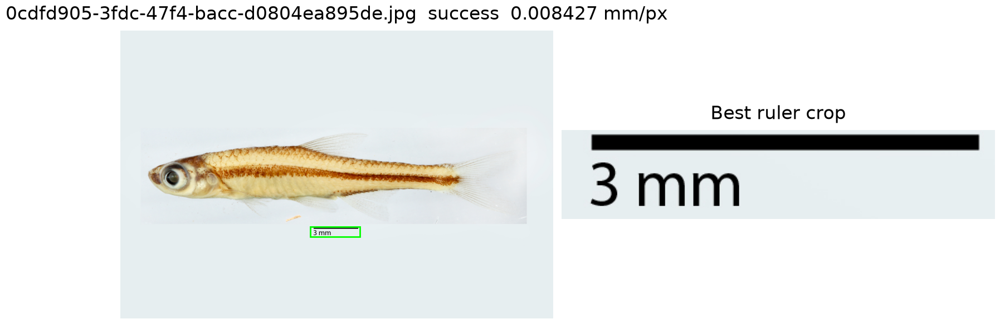

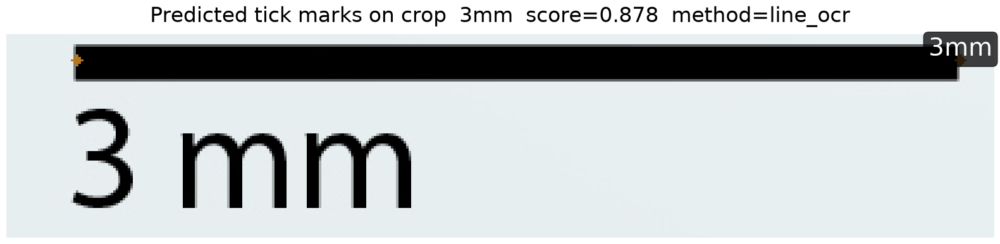

16044_plantclef.jpg  0.1741 mm/px


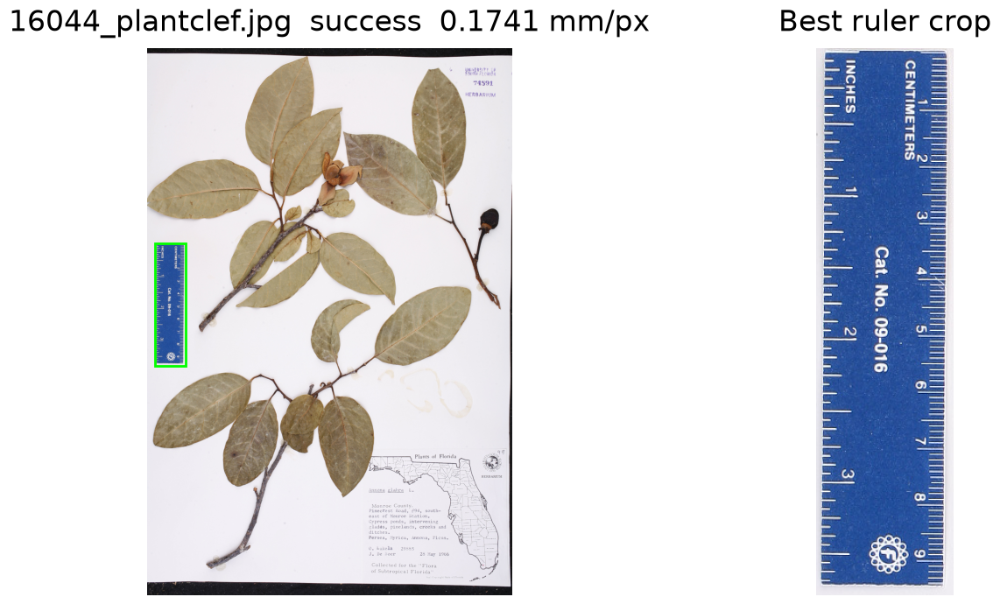

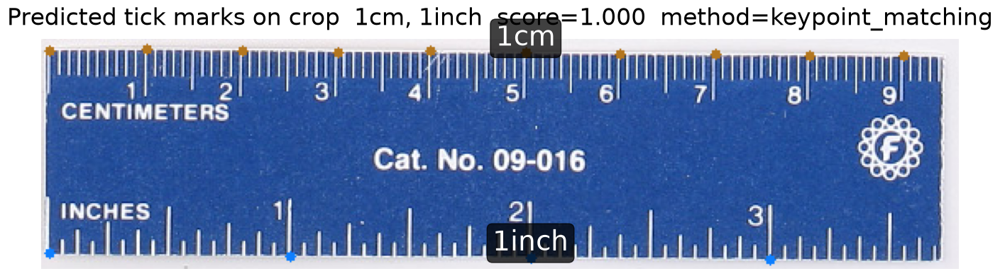

19061_plantclef.jpg  0.09208 mm/px


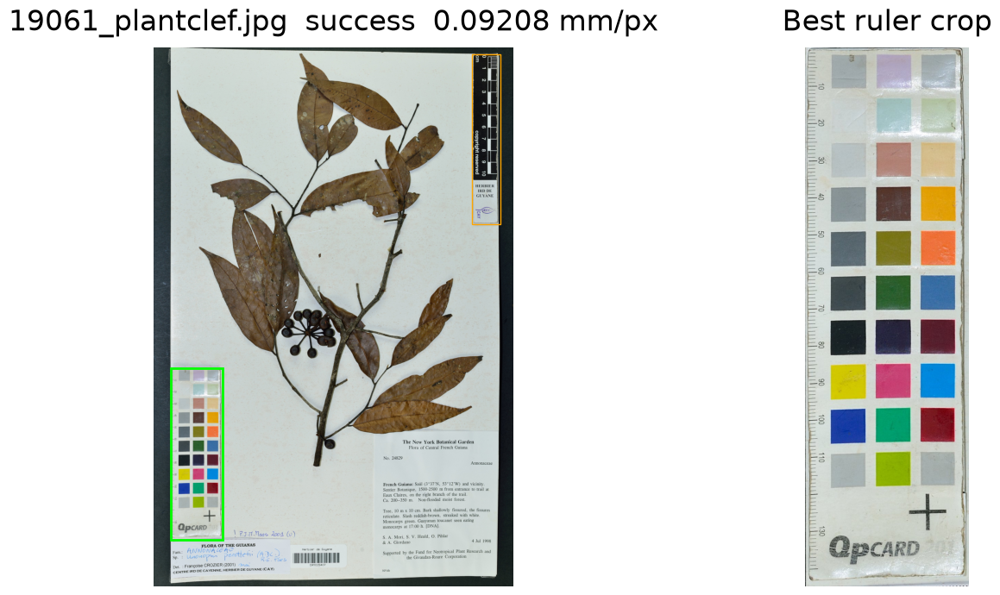

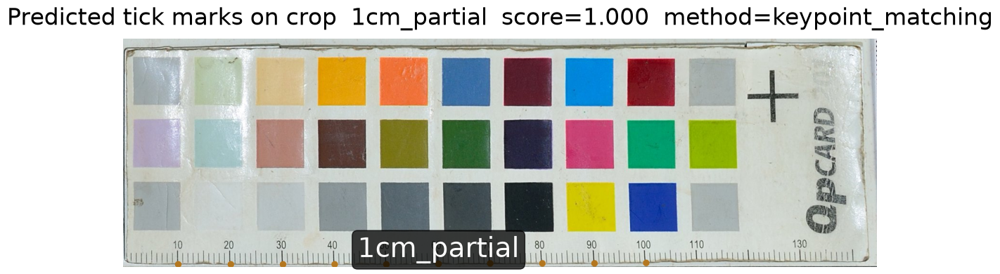

2c96f175-2b64-49f2-b95e-d21cf63c0a88.jpg  0.2539 mm/px


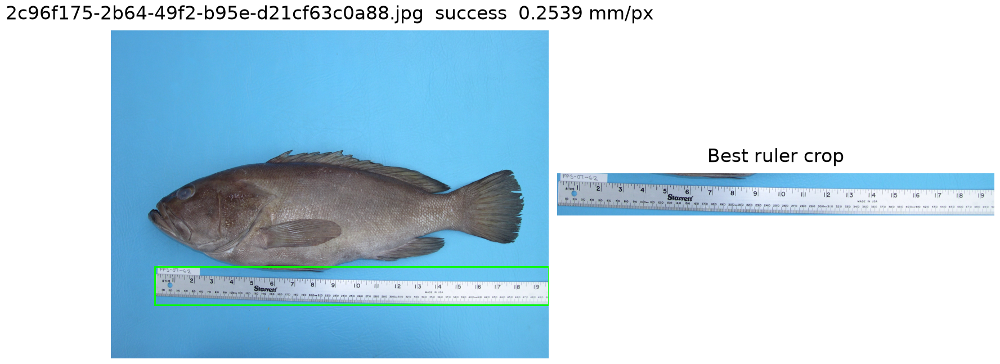

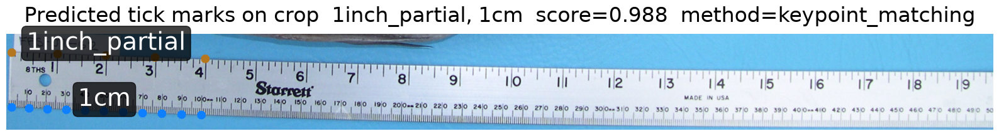

3357379674.jpg  0.07708 mm/px


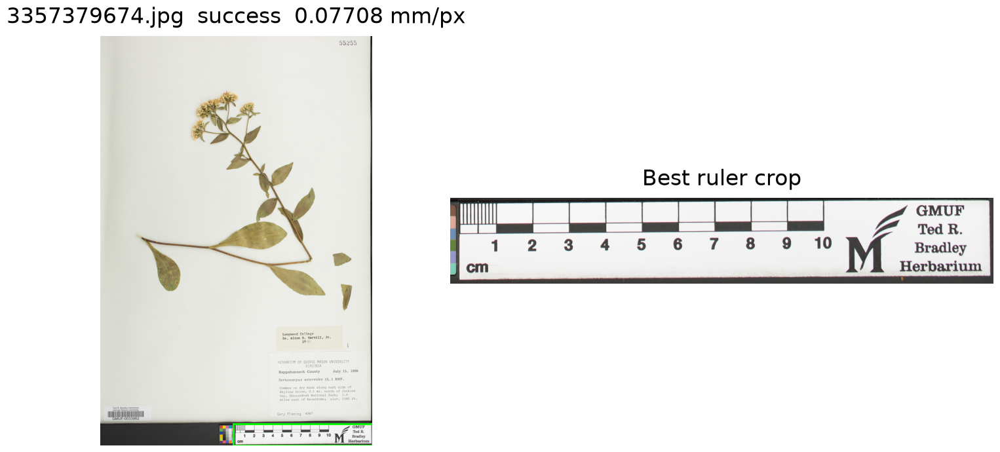

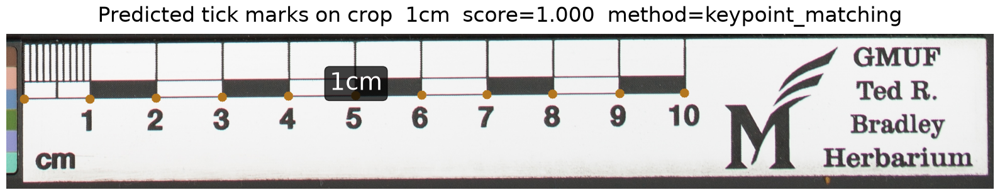

3698755863.jpg  0.07969 mm/px


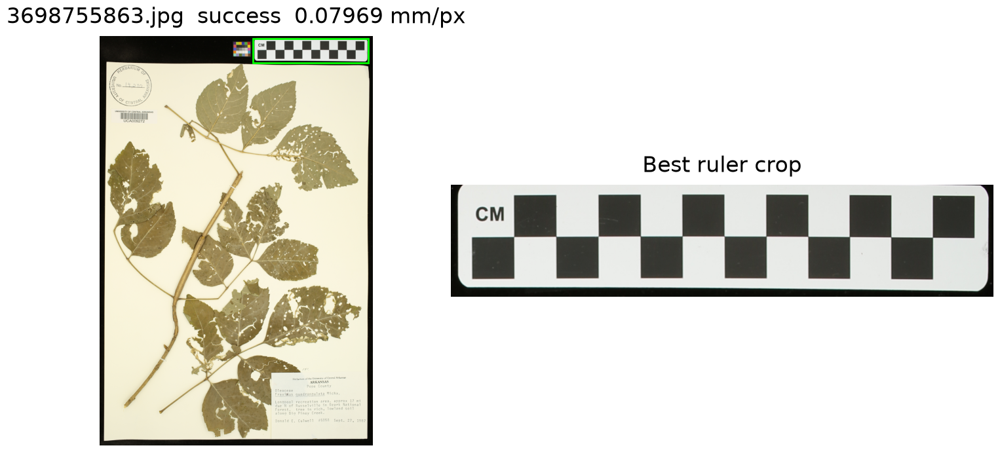

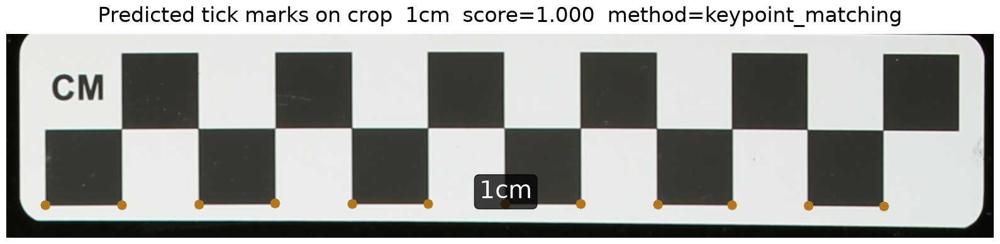

4066427438.jpg  0.0639 mm/px


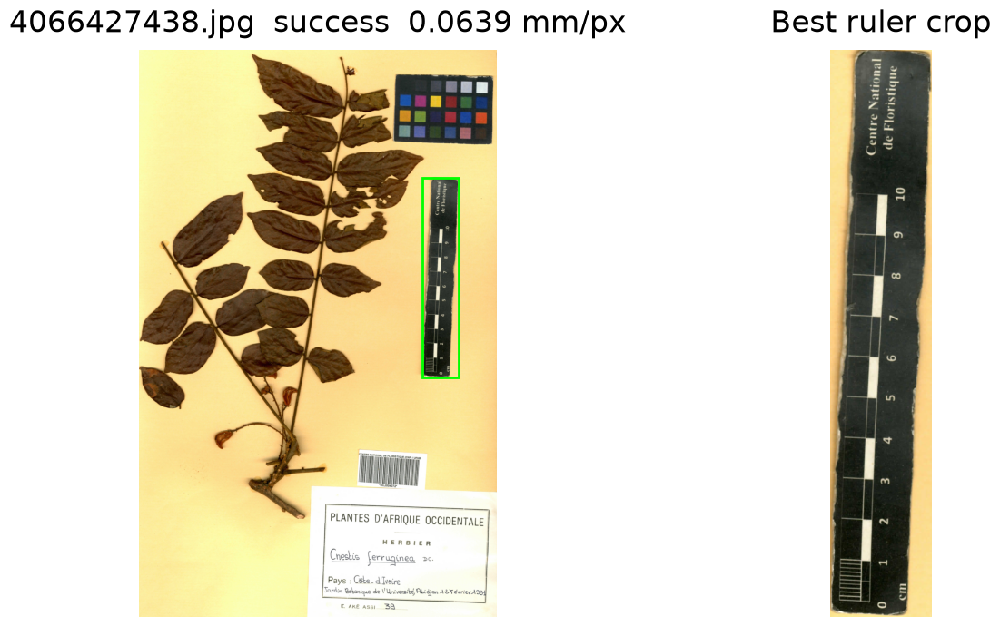

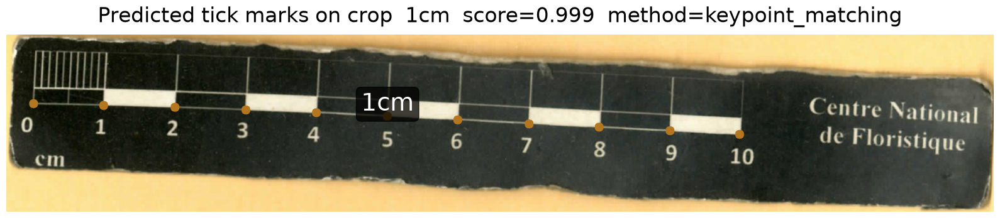

4092603860.jpg  0.1113 mm/px


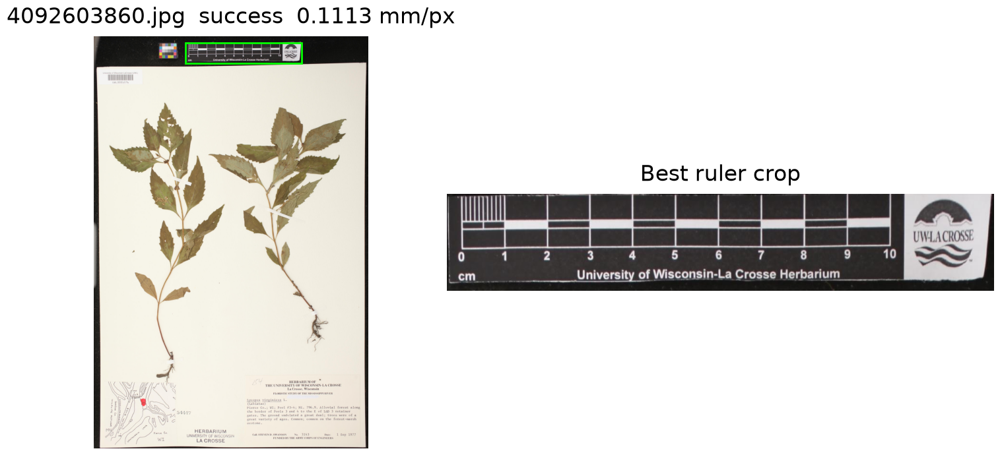

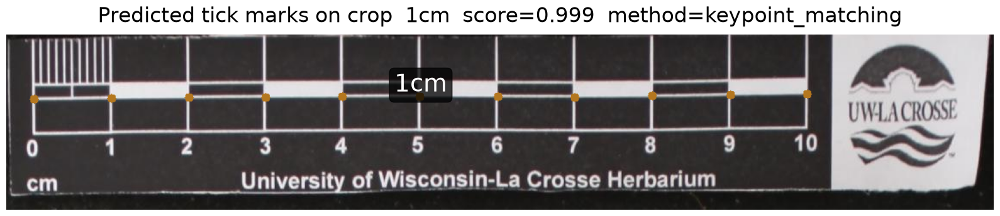

4160978316.jpg  0.07213 mm/px


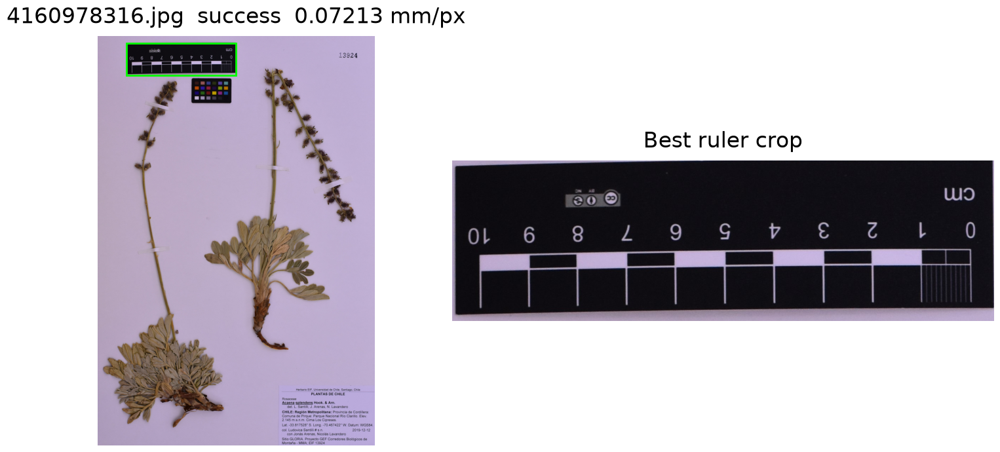

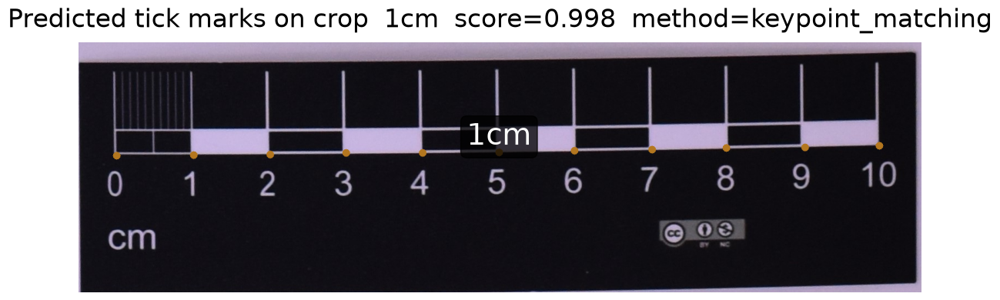

574791687.jpg  0.1784 mm/px


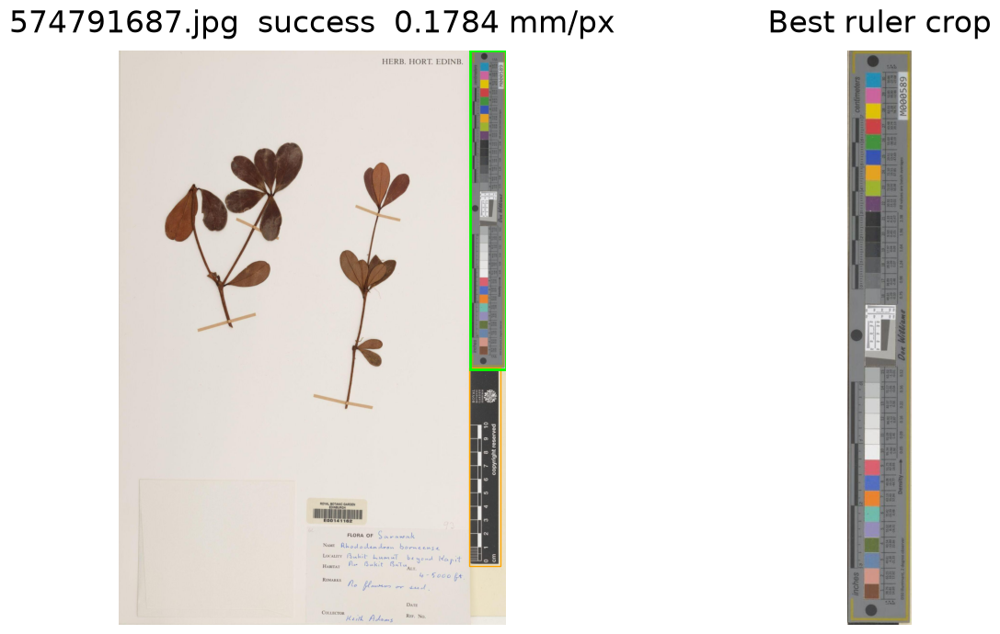

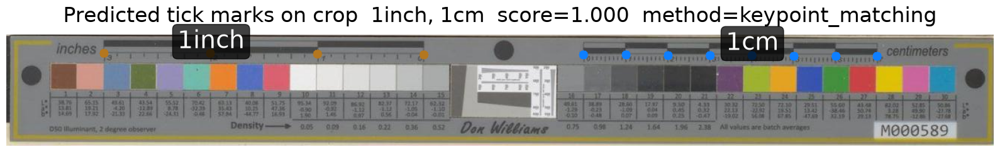

In [9]:
if not IMAGE_DIR.is_dir():
    raise FileNotFoundError(IMAGE_DIR)

images = sorted(
    path for path in IMAGE_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in IMAGE_EXTS
)
if not images:
    raise FileNotFoundError(f"No images in {IMAGE_DIR}")

print(f"Found {len(images)} images to process")

for image_path in images:
    result = engine.predict(image_path)
    if result.scale_factor is not None:
        print(f"{image_path.name}  {result.scale_factor:.4g} {engine.target_unit}/px")
    else:
        print(f"{image_path.name}  {result.status}")
    out_path = OUTPUT_DIR / f"{image_path.stem}.json"
    out_path.write_text(json.dumps(result.to_dict(), indent=2), encoding="utf-8")
    show_result(image_path, result.detection_results.to_dict(), result)
